<a href="https://colab.research.google.com/github/ID9999999999999/naziherrahel-Deep-Learning-for-Computer-Vision/blob/main/Labs/Obj_detection/Lab12/lab12_train_evaluate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Tue Nov 24 00:16:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!git clone https://github.com/ID9999999999999/naziherrahel-Deep-Learning-for-Computer-Vision.git

Cloning into 'naziherrahel-Deep-Learning-for-Computer-Vision'...
remote: Enumerating objects: 365, done.
remote: Counting objects: 100% (249/249), done.
remote: Compressing objects: 100% (215/215), done.
remote: Total 365 (delta 71), reused 47 (delta 5), pack-reused 116 (from 1)
Receiving objects: 100% (365/365), 26.27 MiB | 16.31 MiB/s, done.
Resolving deltas: 100% (103/103), done.


In [ ]:
%cd /content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12

/content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12


In [3]:
%pip install --no-cache-dir --upgrade "numpy==2.2.6" "albumentations==1.4.24" "ultralytics==8.3.200"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 45.8 MB/s  0:00:00
  Attempting uninstall: ultralytics
    Found existing installation: ultralytics 8.3.0
    Uninstalling ultralytics-8.3.0:
      Successfully uninstalled ultralytics-8.3.0


In [4]:
import numpy
import torch
import cv2
import albumentations
import ultralytics

print("NumPy:", numpy.__version__)
print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("Albumentations:", albumentations.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
NumPy: 2.2.6
PyTorch: 2.14.1+cu130
OpenCV: 4.11.0
Albumentations: 1.4.24
Ultralytics: 8.3.200
GPU: True


/usr/local/lib/python3.13/dist-packages/albumentations/__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.24). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


In [6]:
from pathlib import Path
import importlib
import sys
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

lab_root = Path("/content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12")

assert lab_root.exists(), "Lab12 folder not found"

sys.path.insert(0, str(lab_root))

import detection_dataset as dd
importlib.reload(dd)

workspace = lab_root / "work"
workspace.mkdir(exist_ok=True)

print("Lab root:", lab_root)
print("Workspace:", workspace)
print("Initialization successful.")

Lab root: /content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12
Workspace: /content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12/work
Initialization successful.


Dataset: /content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12/work/pennfudan_yolo_augmented
YAML: /content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12/work/pennfudan_yolo_augmented/data.yaml
Summary: {'train': {'images': 238, 'boxes': 582}, 'val': {'images': 26, 'boxes': 68}, 'test': {'images': 25, 'boxes': 64}}
GPU: True


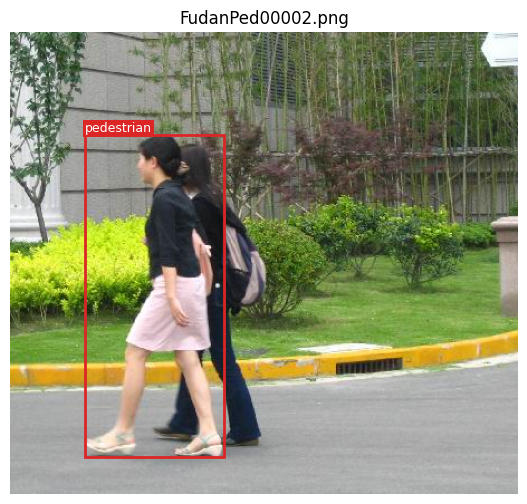

SUCCESS


In [8]:
from pathlib import Path
import sys
import torch
import matplotlib.pyplot as plt

lab_root = Path("/content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12")

assert lab_root.exists(), "Lab12 folder not found"

sys.path.insert(0, str(lab_root))

import detection_dataset as dd

workspace = lab_root / "work"
workspace.mkdir(exist_ok=True)

lab11_dataset_root = lab_root.parent / "Lab11" / "work" / "pennfudan_yolo_augmented"

if (lab11_dataset_root / "data.yaml").exists():
    dataset_root = lab11_dataset_root
else:
    source_root = dd.download_pennfudan(workspace / "source")

    base_dataset_root = dd.prepare_base_dataset(
        source_root,
        workspace / "pennfudan_yolo",
        seed=2026
    )

    dataset_root = dd.make_augmented_dataset(
        base_dataset_root,
        workspace / "pennfudan_yolo_augmented",
        seed=2026
    )

data_yaml = dd.write_dataset_yaml(dataset_root)
dataset_summary = dd.validate_yolo_dataset(dataset_root)

print("Dataset:", dataset_root)
print("YAML:", data_yaml)
print("Summary:", dataset_summary)
print("GPU:", torch.cuda.is_available())

image_array, class_ids, boxes, image_path = dd.load_yolo_sample(
    dataset_root, "train", index=0
)

figure, axes = plt.subplots(figsize=(7, 6))
dd.plot_yolo_sample(axes, image_array, class_ids, boxes)
axes.set_title(image_path.name)
plt.show()

print("SUCCESS")

In [9]:
if not torch.cuda.is_available():
    raise RuntimeError(
        'No GPU was detected. Enable a GPU runtime, then run this notebook again.'
    )

print('GPU:', torch.cuda.get_device_name(0))
print('CUDA version:', torch.version.cuda)

GPU: Tesla T4
CUDA version: 13.0


In [10]:
from ultralytics import YOLO

run_root = workspace / 'runs'
run_name = 'pedestrian_yolo11n'

model = YOLO('yolo11n.pt')

training_result = model.train(
    data=str(data_yaml),
    epochs=10,
    imgsz=512,
    batch=16,
    device=0,
    workers=2,
    seed=2026,
    deterministic=True,
    project=str(run_root),
    name=run_name,
    exist_ok=True,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    degrees=0.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.0,
    mosaic=0.0,
    mixup=0.0,
    verbose=True,
)

run_dir = run_root / run_name
best_weights = run_dir / 'weights' / 'best.pt'

if not best_weights.exists():
    raise FileNotFoundError(
        f'Could not find trained weights at {best_weights}'
    )

print('Best weights:', best_weights)

New https://pypi.org/project/ultralytics/8.4.218 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.200 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12/work/pennfudan_yolo_augmented/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, m

In [11]:
best_model = YOLO(best_weights)

validation_metrics = best_model.val(
    data=str(data_yaml),
    split='val',
    imgsz=512,
    batch=16,
    device=0,
    plots=True,
    project=str(run_root),
    name=f'{run_name}_validation',
    exist_ok=True,
)

test_metrics = best_model.val(
    data=str(data_yaml),
    split='test',
    imgsz=512,
    batch=16,
    device=0,
    plots=True,
    project=str(run_root),
    name=f'{run_name}_test',
    exist_ok=True,
)

print(f"Validation mAP@0.50: {validation_metrics.box.map50:.4f}")
print(f"Validation mAP@0.50:0.95: {validation_metrics.box.map:.4f}")
print(f"Test mAP@0.50: {test_metrics.box.map50:.4f}")
print(f"Test mAP@0.50:0.95: {test_metrics.box.map:.4f}")

Ultralytics 8.3.200 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2637.4±509.3 MB/s, size: 274.2 KB)
val: Scanning /content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12/work/pennfudan_yolo_augmented/val/labels.cache... 26 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 45.7Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.5it/s 1.3s
                   all         26         68       0.98      0.897      0.968      0.795
Speed: 3.4ms preprocess, 5.7ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to /content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12/work/runs/pedestrian_yolo11n_validation
Ultralytics 8.3.200 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
val: Fast

results.png


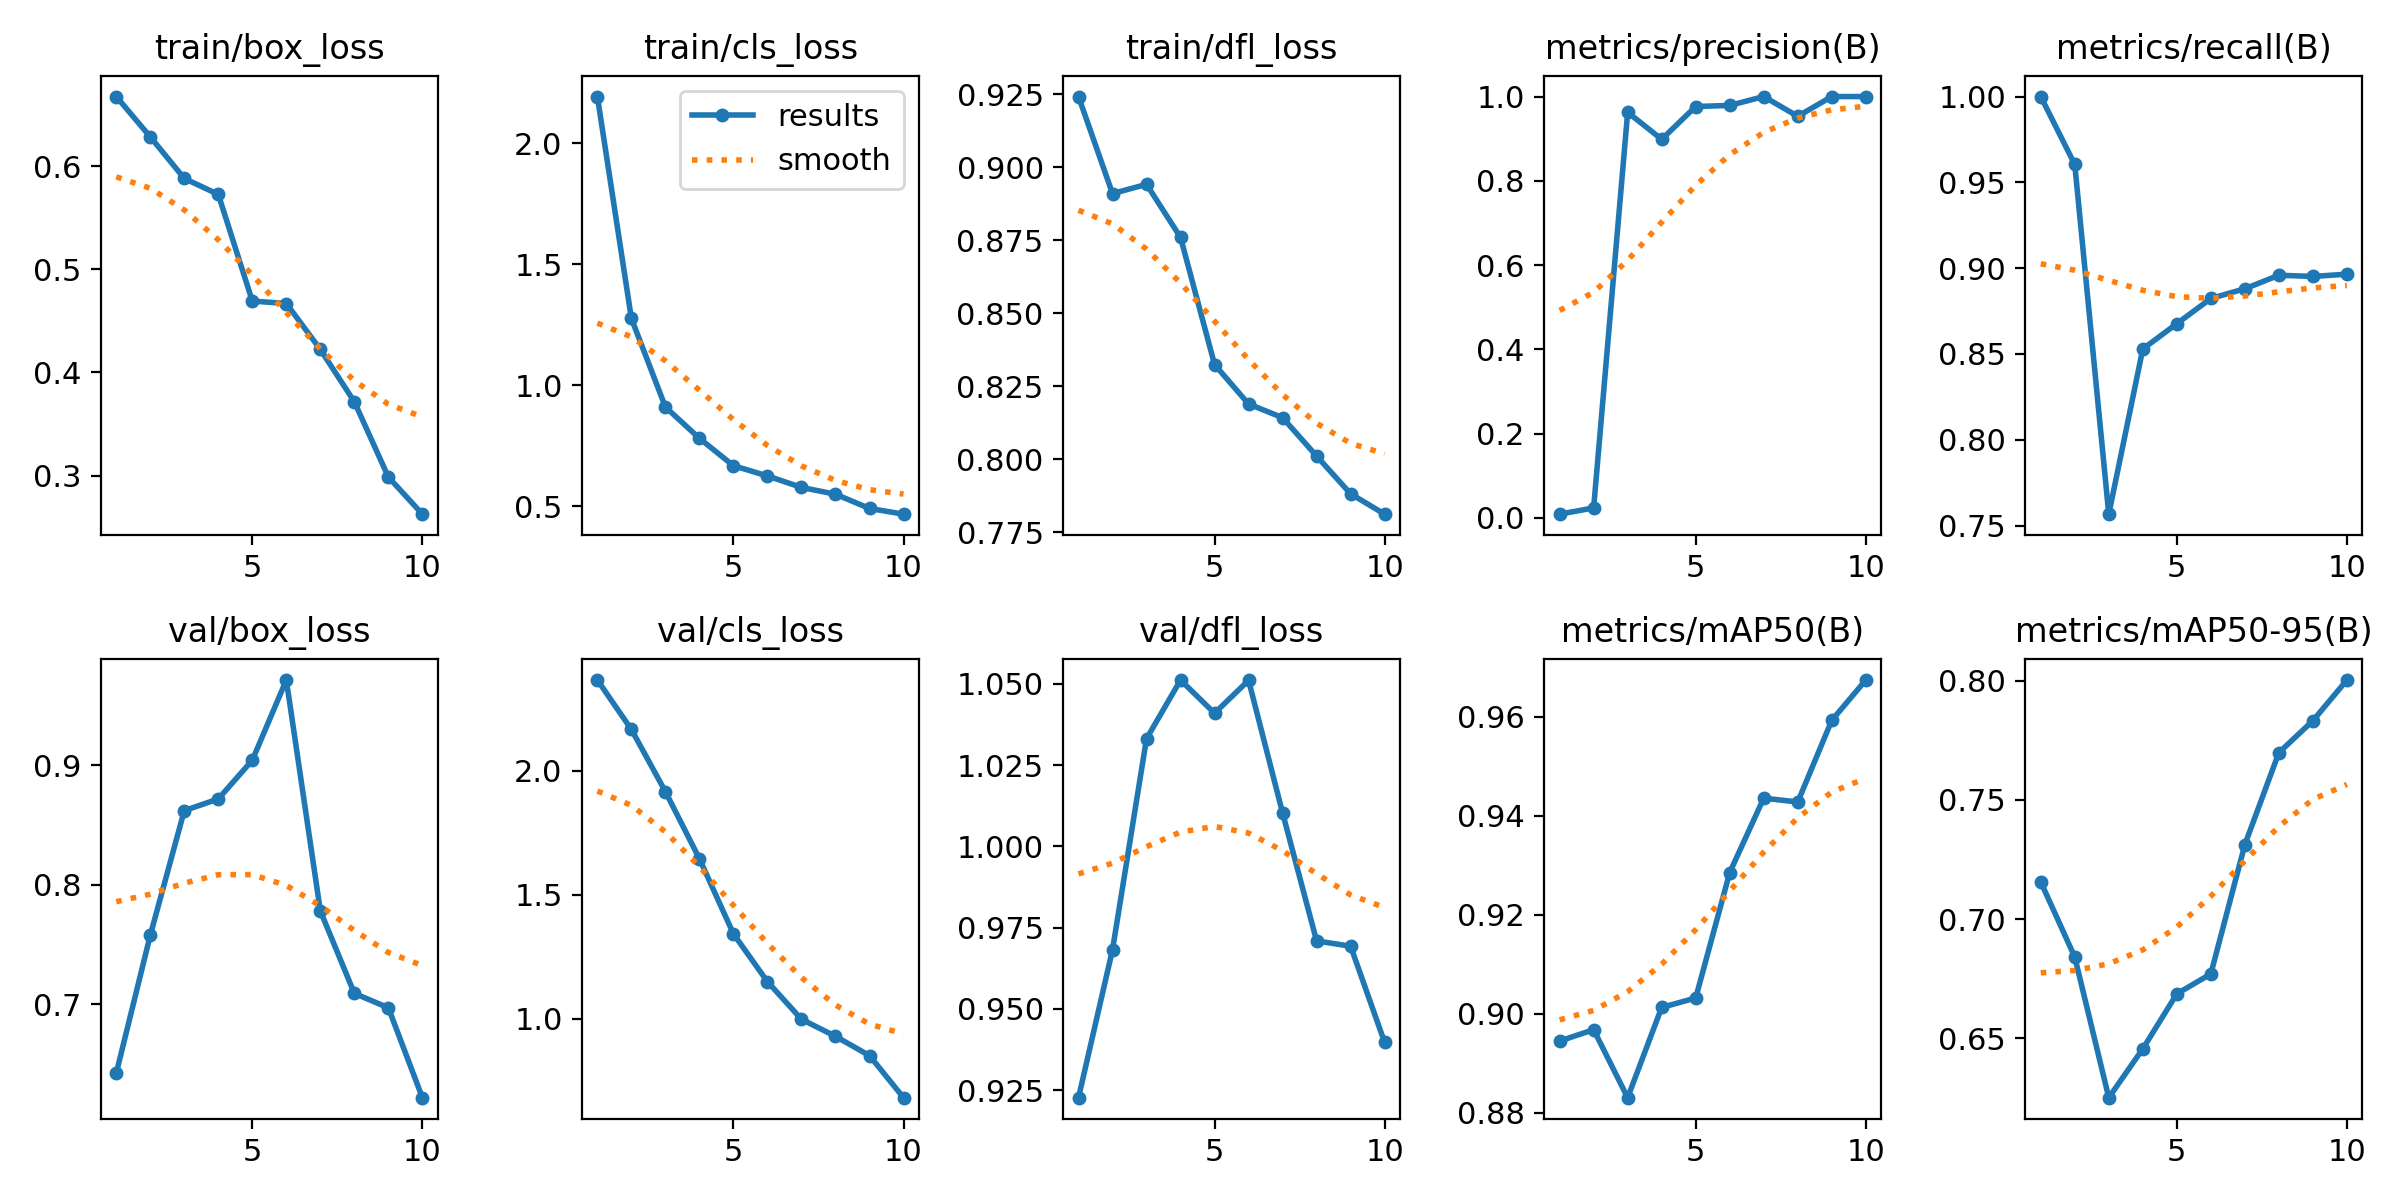

confusion_matrix_normalized.png


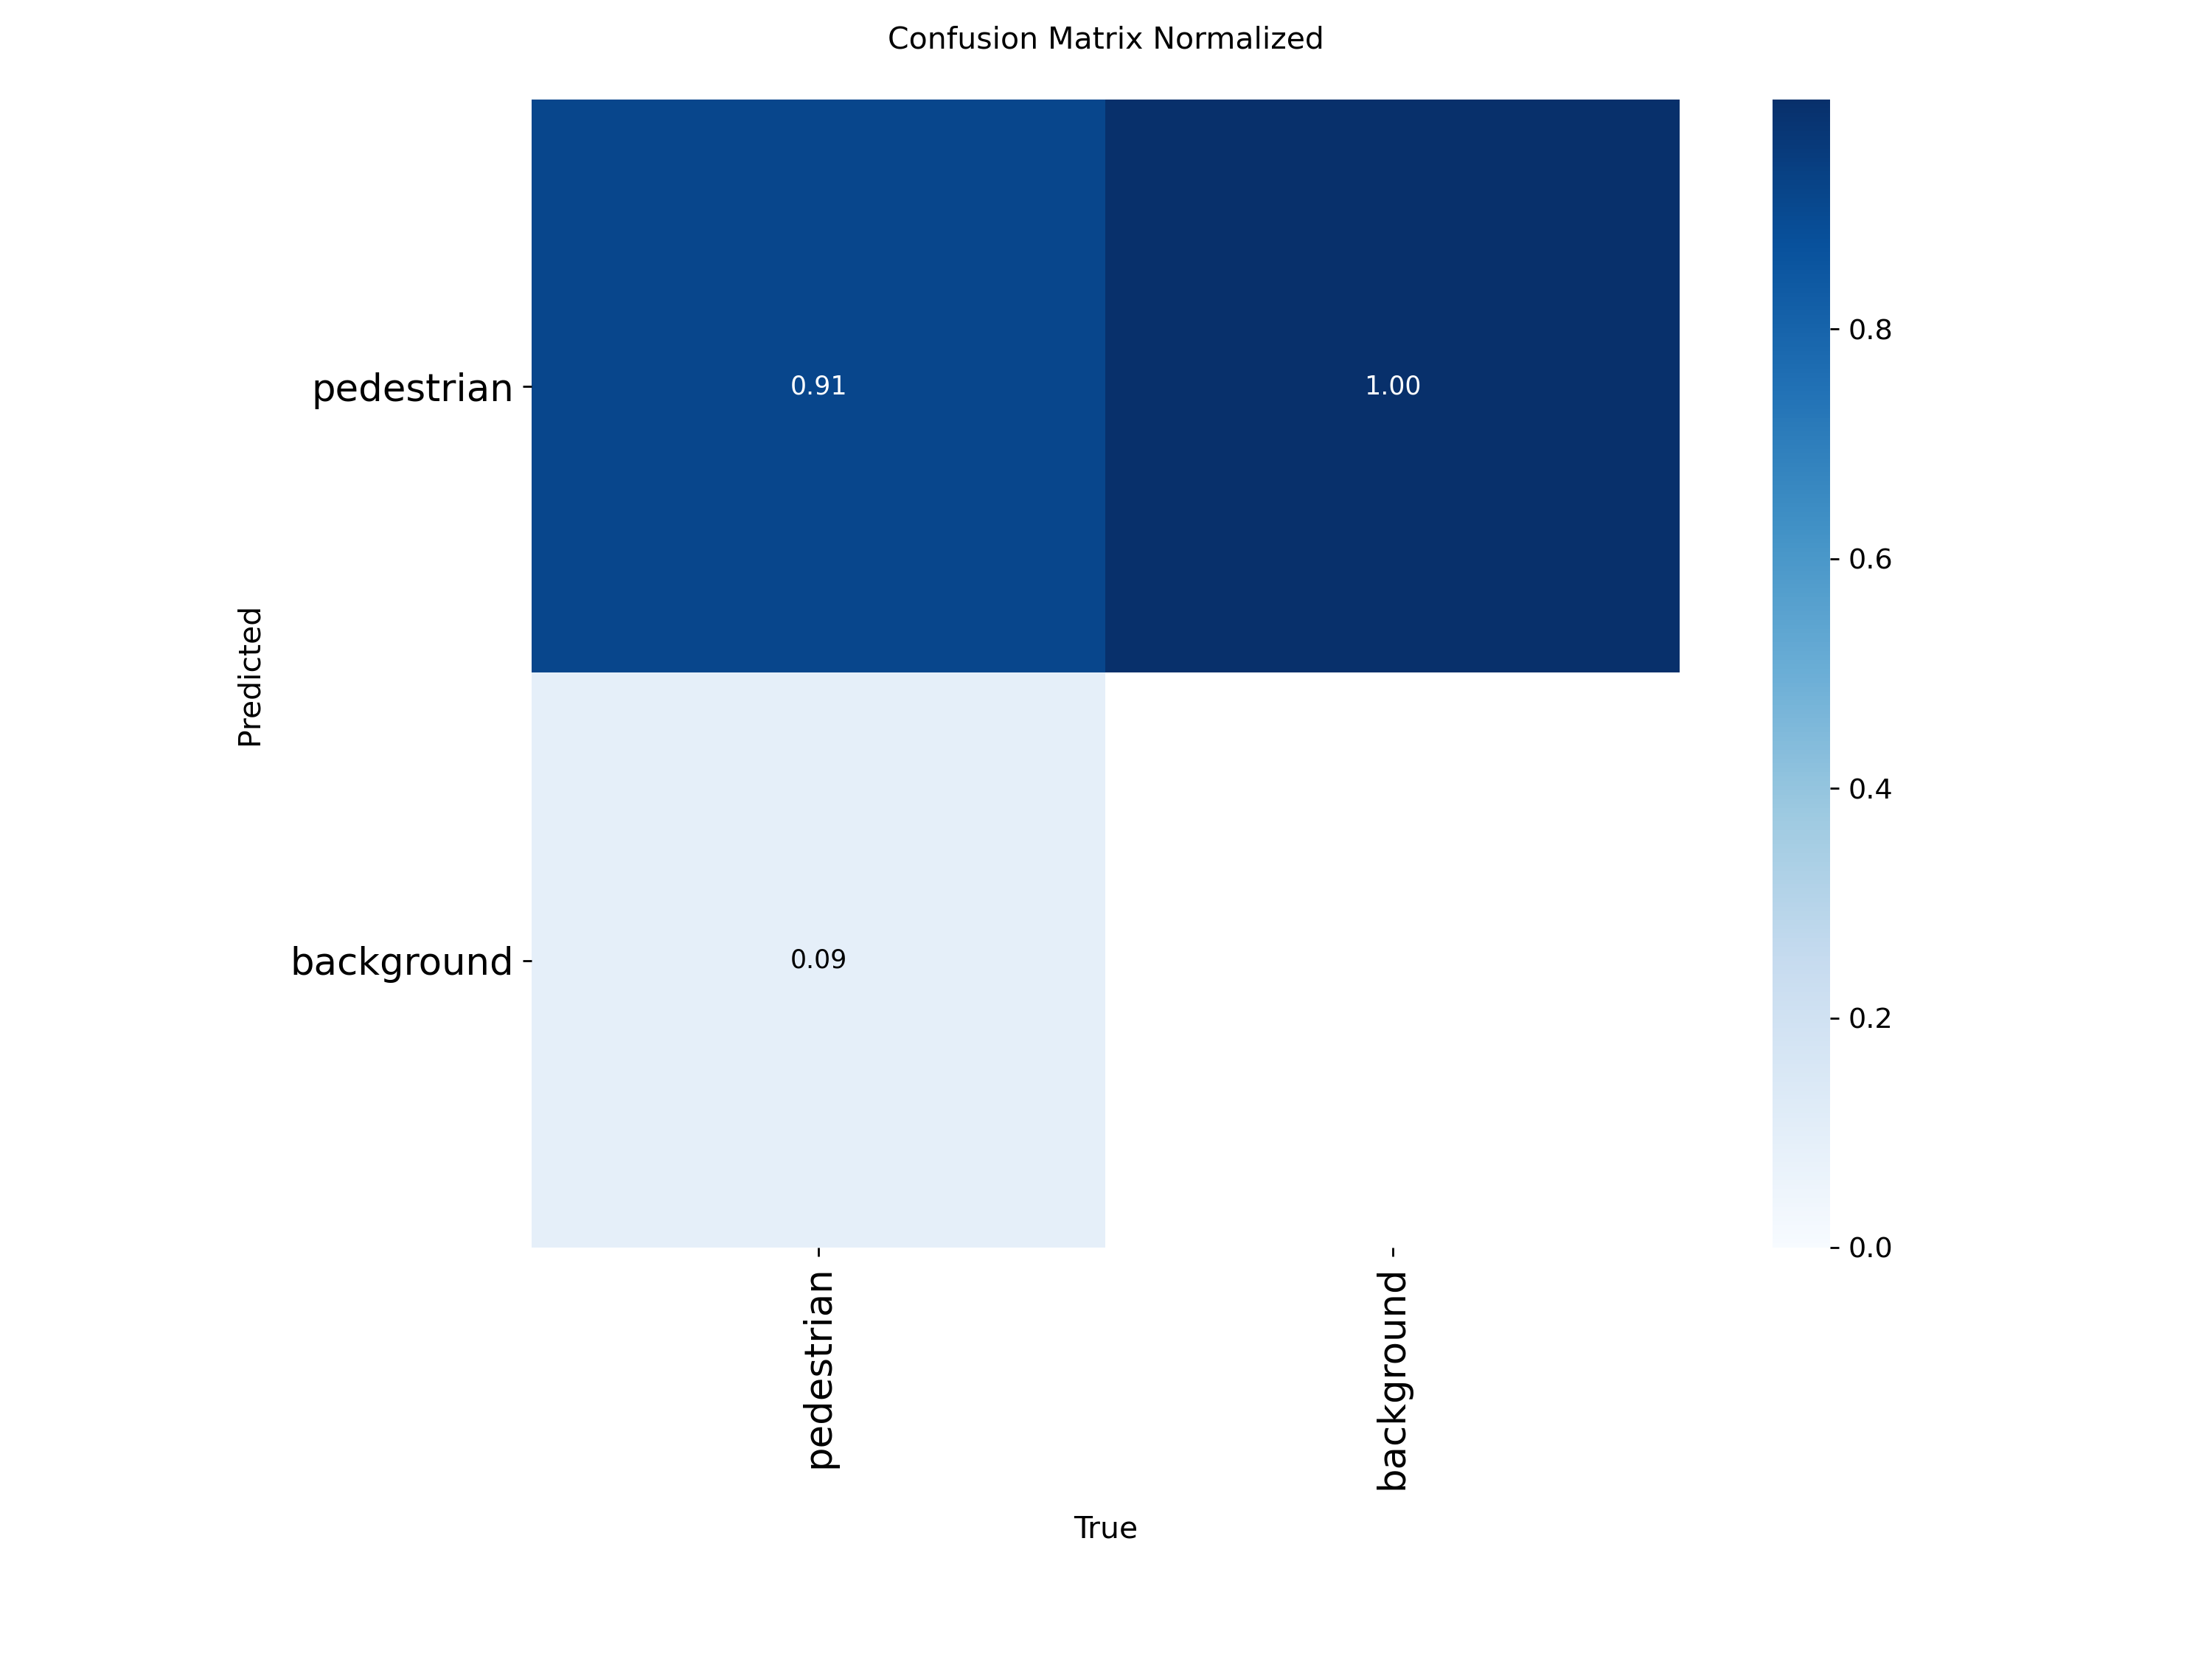

In [12]:
from IPython.display import Image as NotebookImage, display

for filename in (
    'results.png',
    'PR_curve.png',
    'confusion_matrix_normalized.png'
):
    file_path = run_dir / filename

    if file_path.exists():
        print(filename)
        display(NotebookImage(filename=str(file_path)))

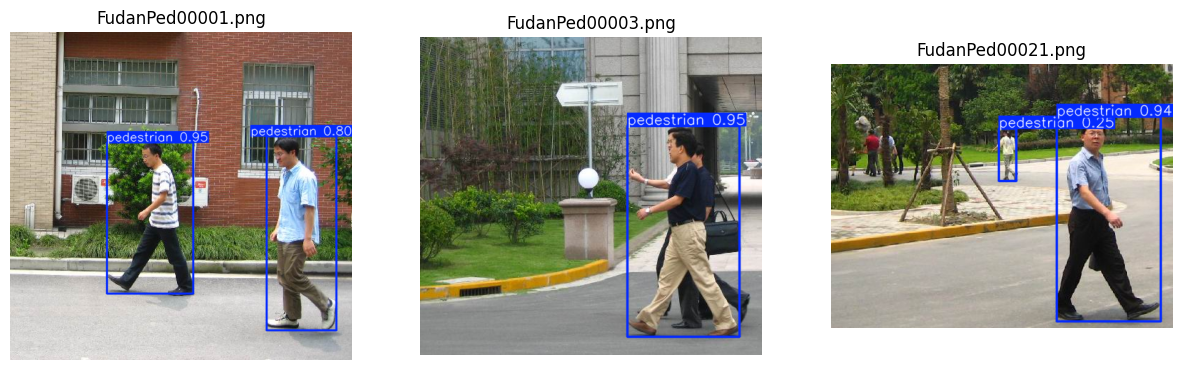

In [13]:
test_images = sorted(
    (dataset_root / 'test' / 'images').glob('*.png')
)[:3]

prediction_results = best_model.predict(
    source=[str(path) for path in test_images],
    imgsz=512,
    conf=0.25,
    device=0,
    verbose=False,
)

figure, axes = plt.subplots(
    1,
    len(prediction_results),
    figsize=(5 * len(prediction_results), 5)
)

if len(prediction_results) == 1:
    axes = [axes]

for axes_item, prediction, image_path in zip(
    axes, prediction_results, test_images
):
    axes_item.imshow(prediction.plot()[:, :, ::-1])
    axes_item.set_title(image_path.name)
    axes_item.axis('off')

plt.show()

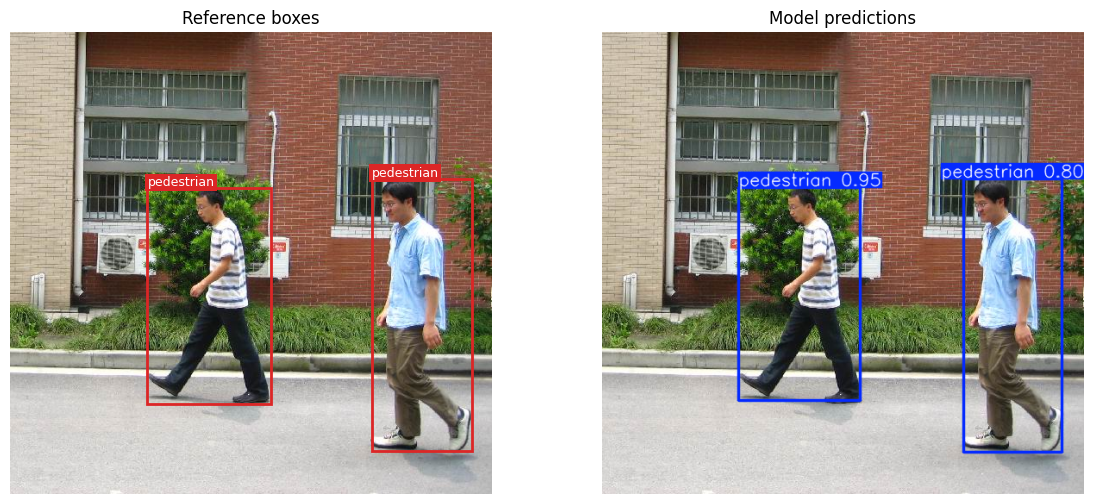

In [14]:
ground_truth_image, ground_truth_classes, ground_truth_boxes, ground_truth_path = dd.load_yolo_sample(
    dataset_root, 'test', index=0
)

first_prediction = prediction_results[0].plot()[:, :, ::-1]

figure, axes = plt.subplots(1, 2, figsize=(14, 6))

dd.plot_yolo_sample(
    axes[0],
    ground_truth_image,
    ground_truth_classes,
    ground_truth_boxes
)

axes[0].set_title('Reference boxes')

axes[1].imshow(first_prediction)
axes[1].set_title('Model predictions')
axes[1].axis('off')

plt.show()

### **Q1. Why is mAP across IoU thresholds usually lower than mAP at IoU 0.50?**

Because higher IoU thresholds require more precise bounding box localization. A detection accepted at IoU 0.50 may be rejected at IoU 0.75 or 0.95.

### **Q2. Compare a test image with its reference boxes. Identify one correct detection and explain any missed or extra detection.**

A correct detection occurs when a predicted bounding box accurately overlaps a reference pedestrian bounding box.

Possible missed detections can result from occlusion, small pedestrian size, or poor visibility.

*We must inspect your actual prediction image to complete this answer accurately.*

### **Q3. Why must test images remain outside both augmentation and training?**

To prevent data leakage and ensure an unbiased evaluation of the model's generalization performance on unseen data.

### **Q4. Name one training-data improvement you would try before changing the model architecture.**

Increase the diversity of training images by including pedestrians under different lighting conditions, backgrounds, scales, poses, and occlusion levels.



Saving pexels-filipeazv-4937603.jpg to pexels-filipeazv-4937603.jpg
Results saved to /content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12/work/student_runs/conf_25
Confidence 0.25: /content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12/work/student_runs/conf_25


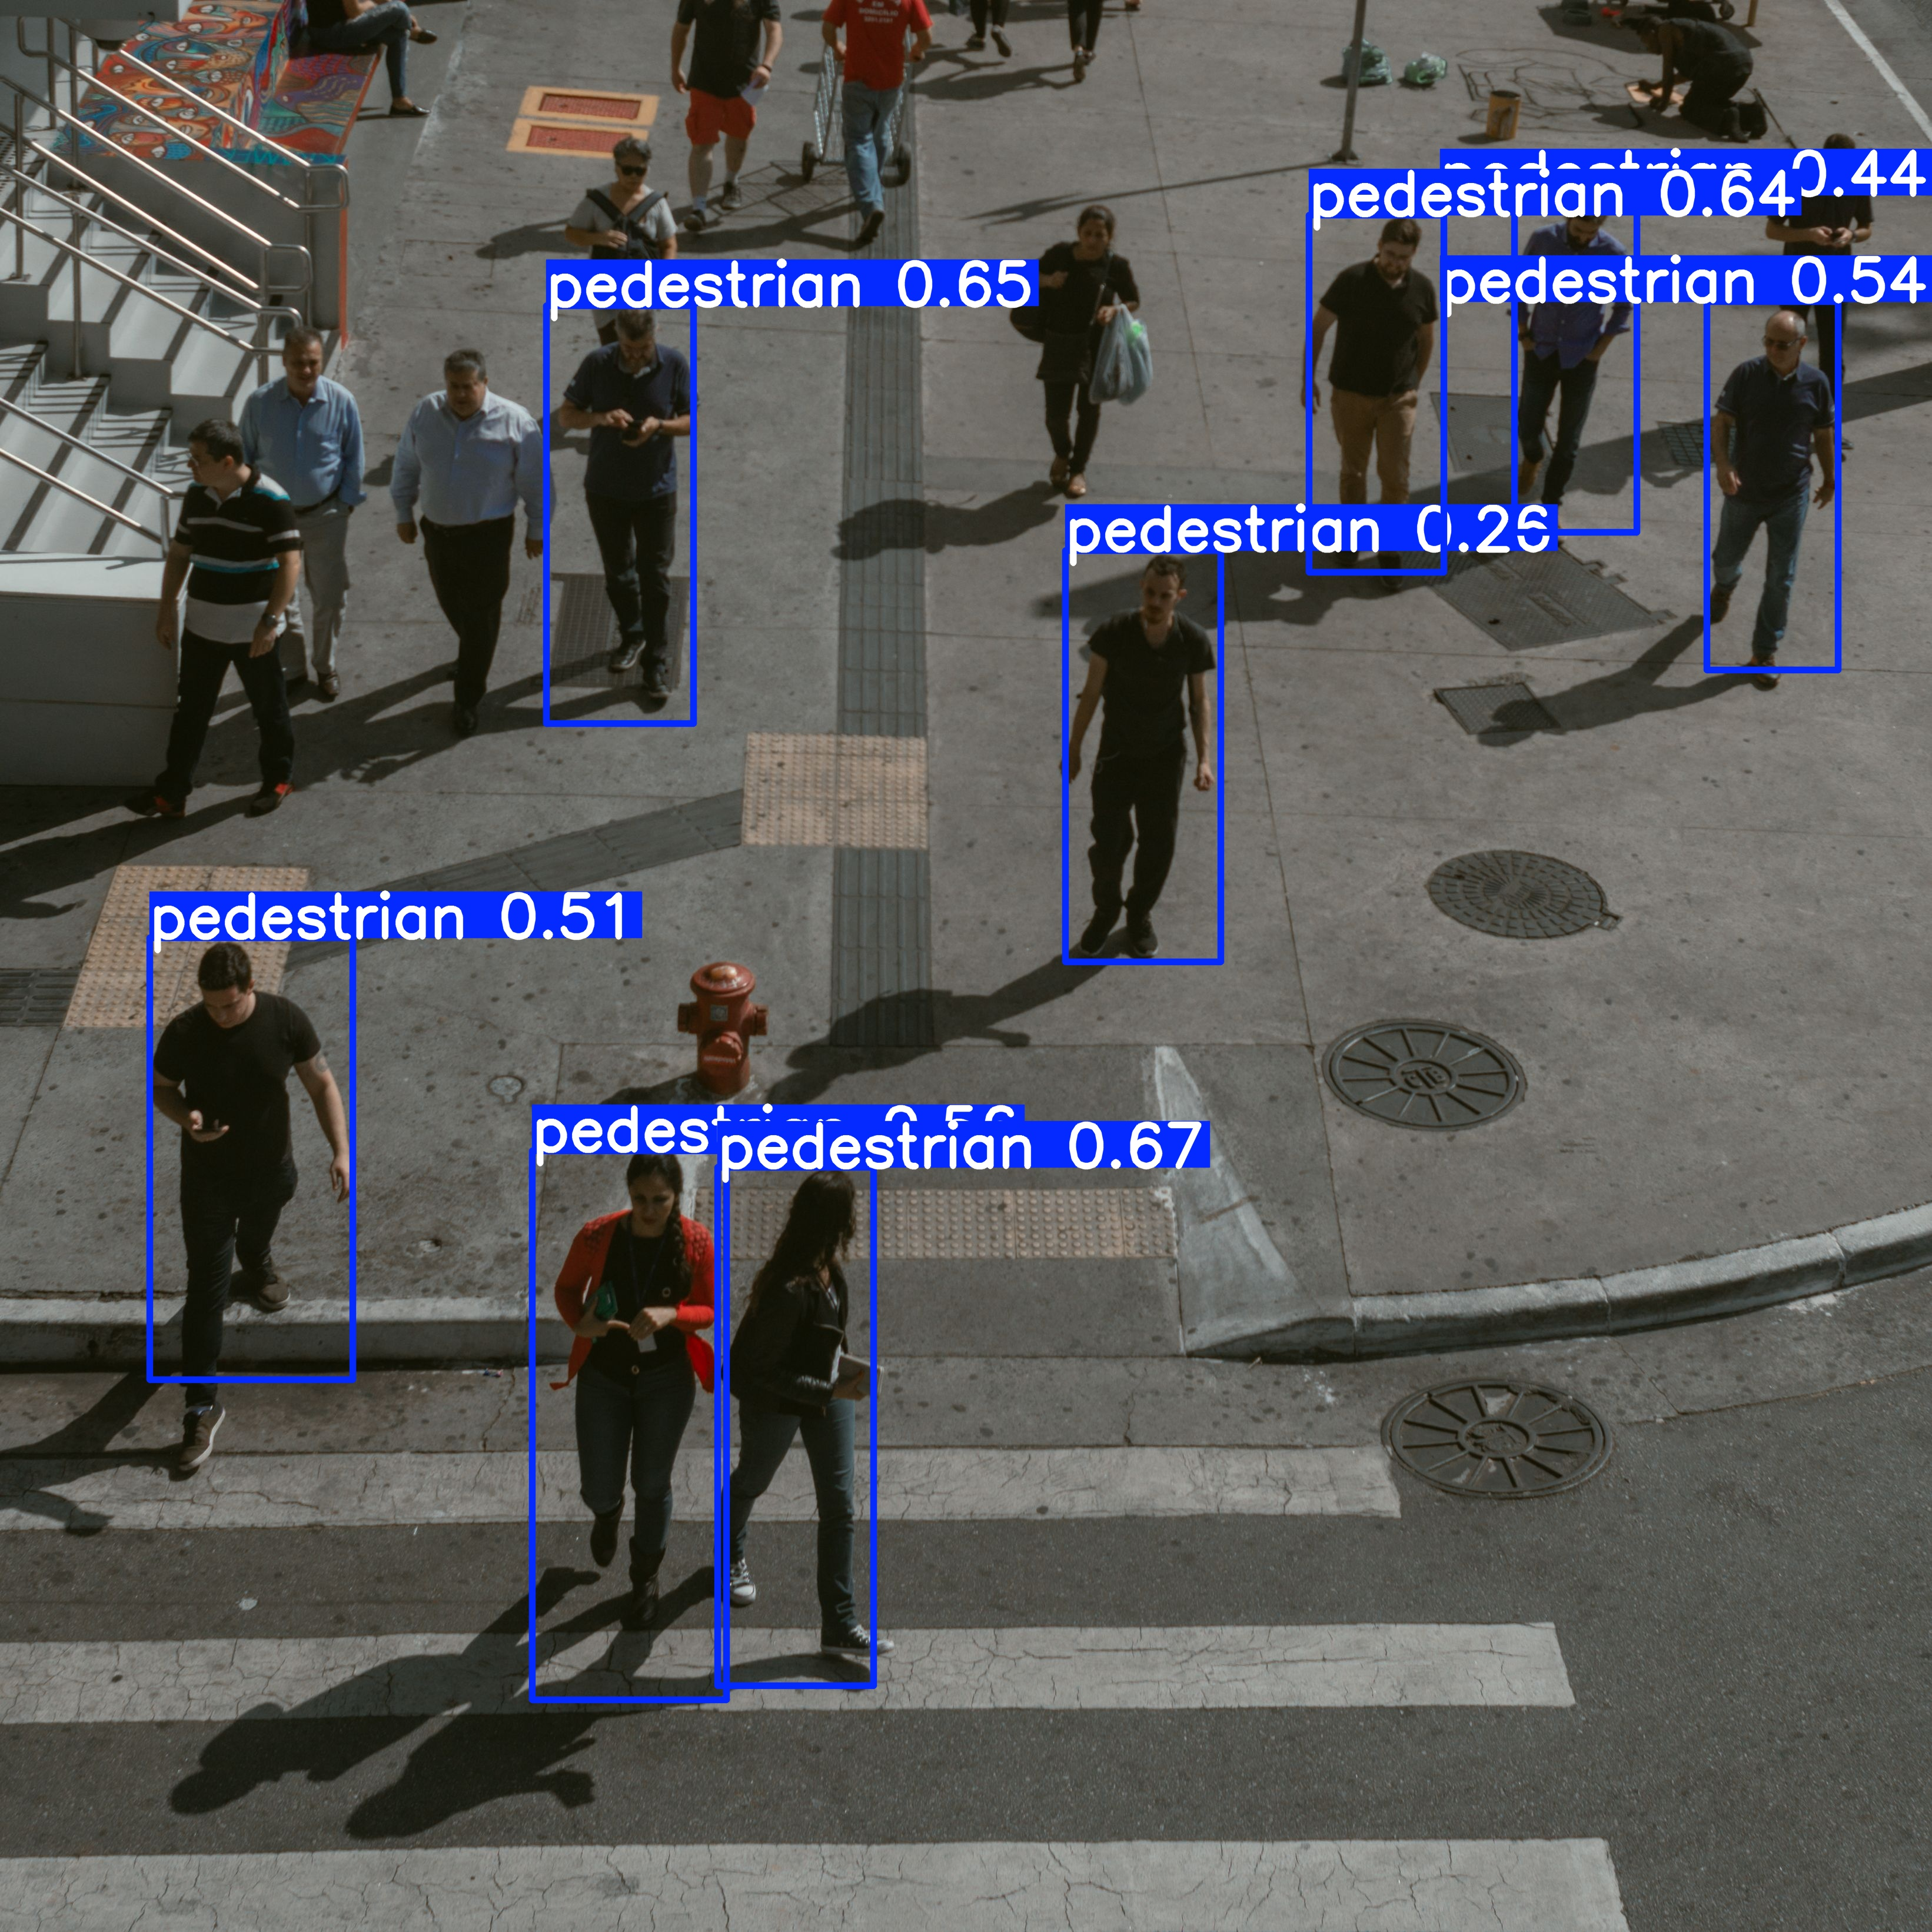

Results saved to /content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12/work/student_runs/conf_50
Confidence 0.50: /content/naziherrahel-Deep-Learning-for-Computer-Vision/Labs/Obj_detection/Lab12/work/student_runs/conf_50


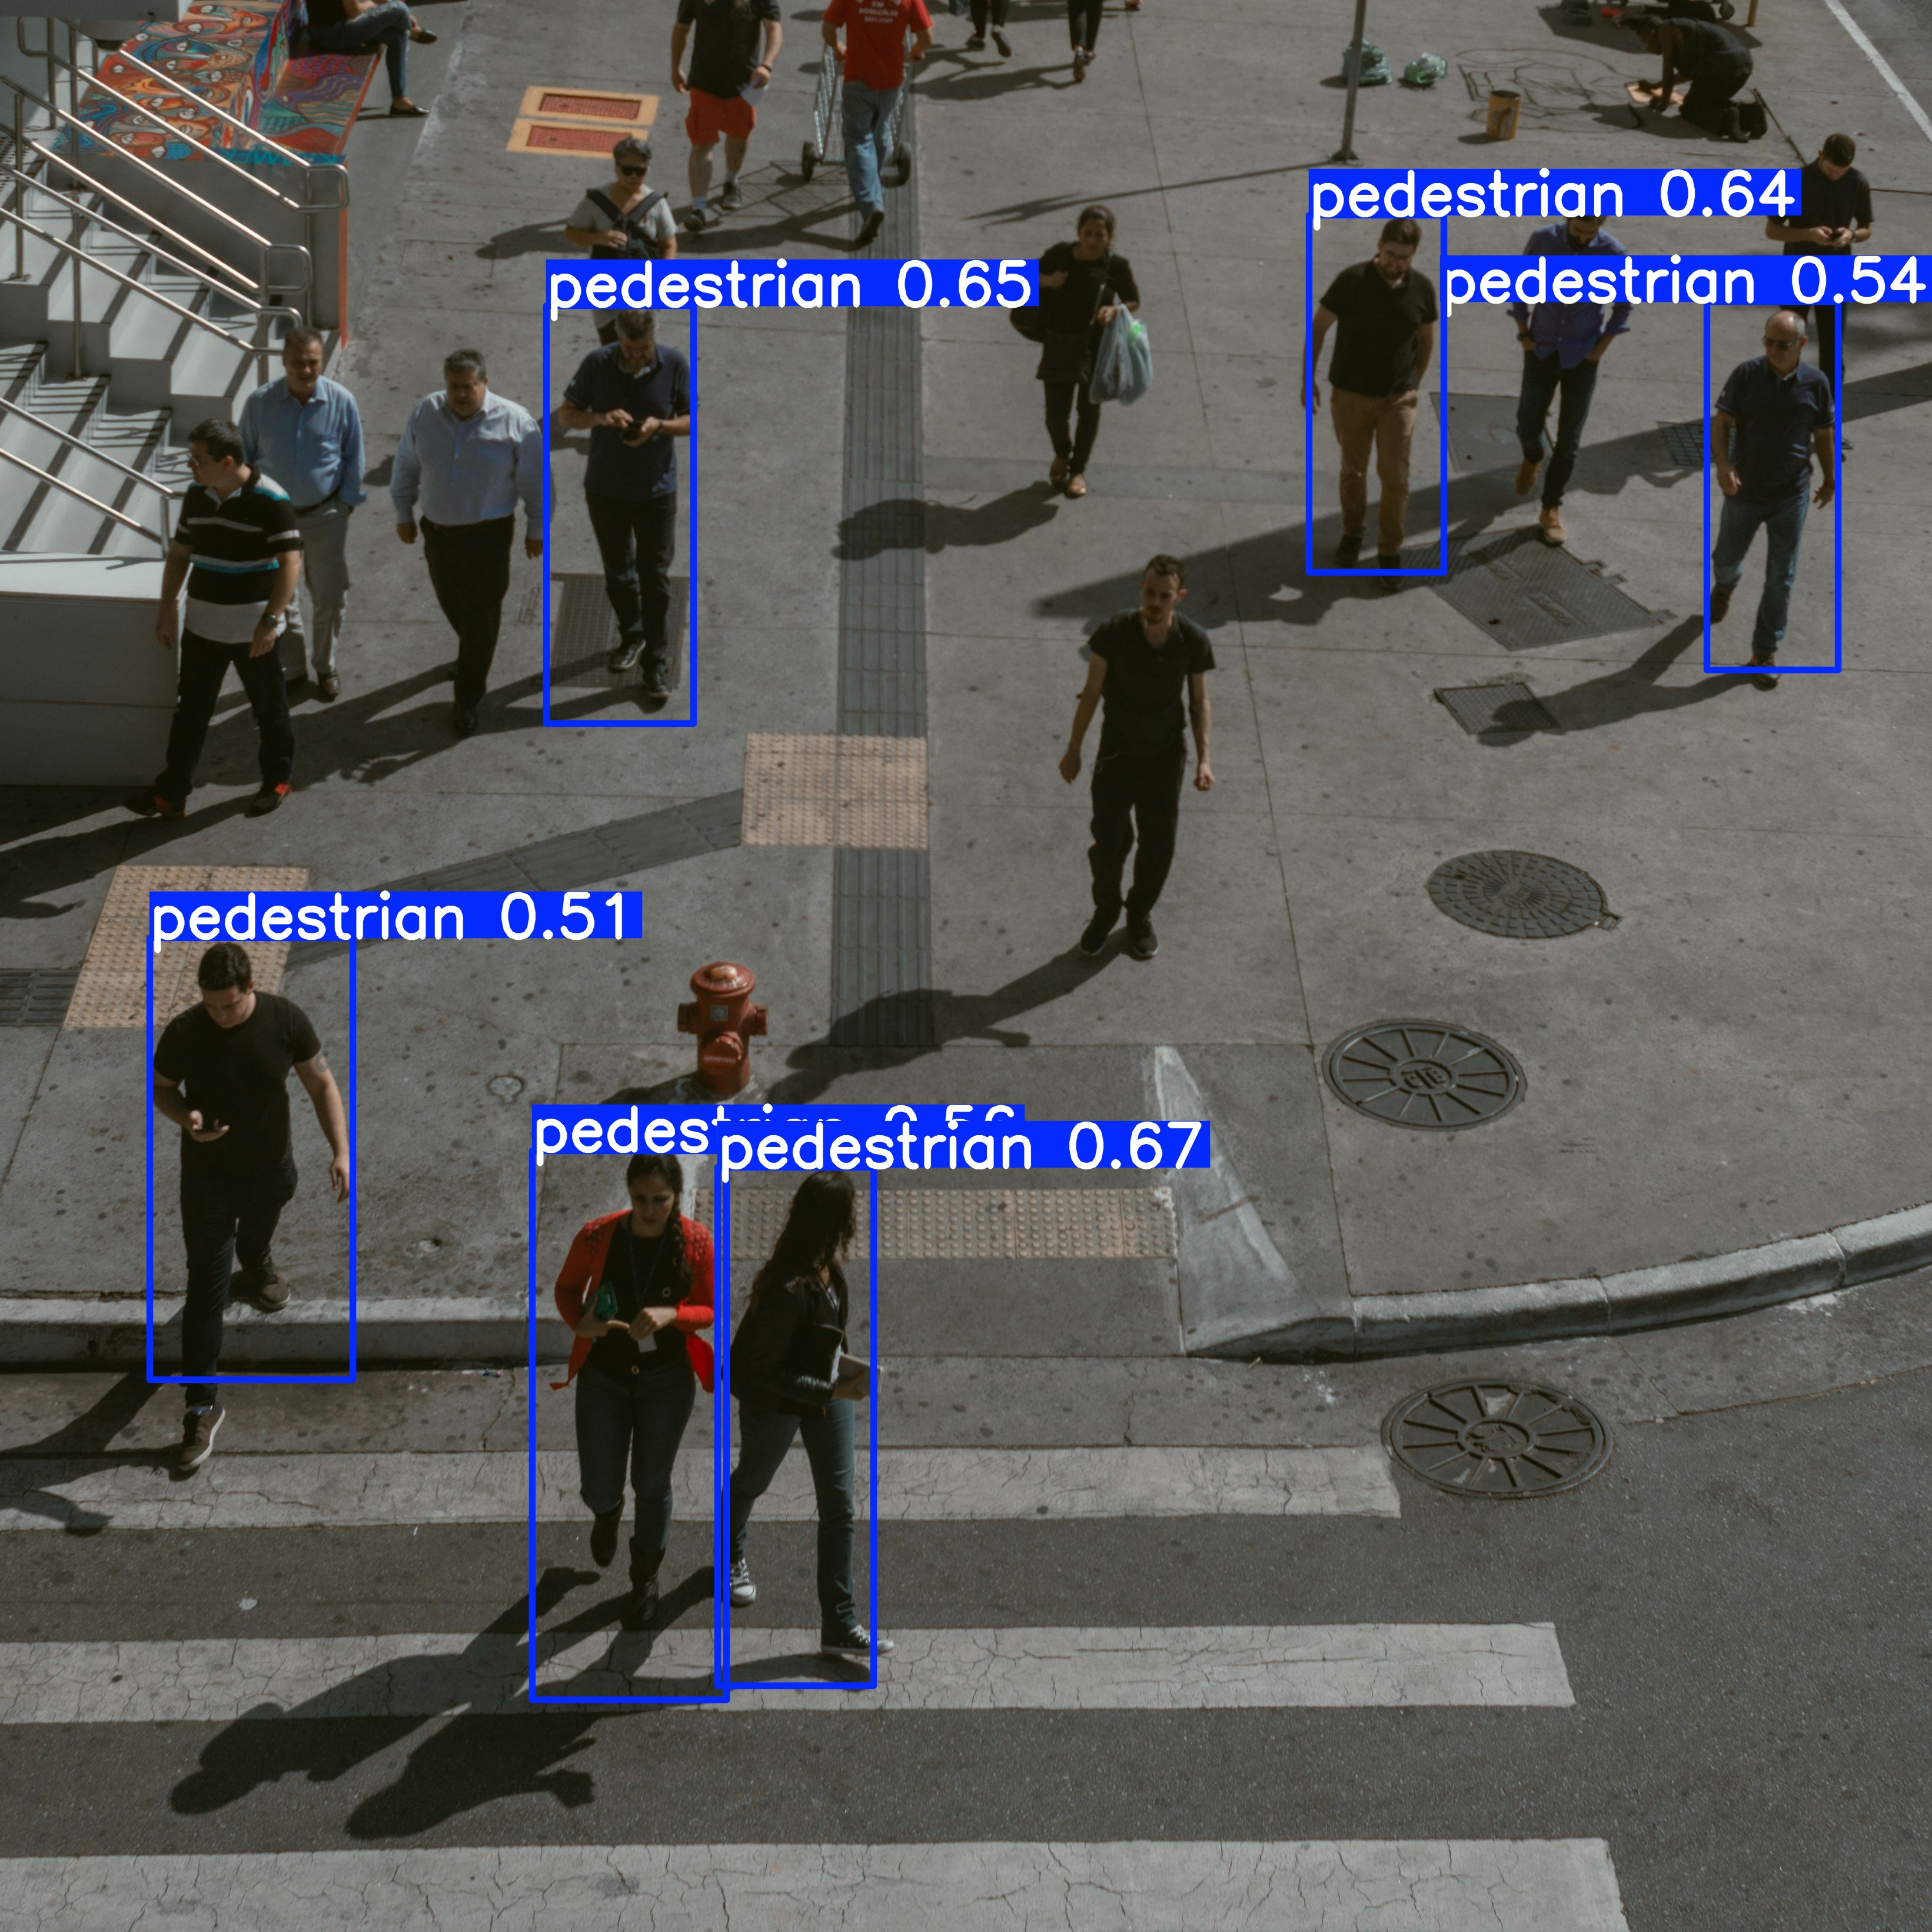

In [15]:
from IPython.display import Image as NotebookImage, display

student_input_dir = workspace / 'student_input'
student_input_dir.mkdir(exist_ok=True)

image_suffixes = {'.jpg', '.jpeg', '.png'}
video_suffixes = {'.mp4', '.mov', '.avi'}
supported_suffixes = image_suffixes | video_suffixes

student_sources = sorted(
    path for path in student_input_dir.iterdir()
    if path.is_file() and path.suffix.lower() in supported_suffixes
)

if not student_sources and 'google.colab' in sys.modules:
    from google.colab import files

    uploaded_files = files.upload()

    for filename, contents in uploaded_files.items():
        (student_input_dir / Path(filename).name).write_bytes(contents)

    student_sources = sorted(
        path for path in student_input_dir.iterdir()
        if path.is_file() and path.suffix.lower() in supported_suffixes
    )

if len(student_sources) != 1:
    print(
        f'Add exactly one image or video to {student_input_dir} before running this task. '
        f'Found {len(student_sources)} supported files.'
    )
else:
    student_source = student_sources[0]
    is_video = student_source.suffix.lower() in video_suffixes
    student_run_root = workspace / 'student_runs'
    student_run_root.mkdir(exist_ok=True)

    for confidence in (0.25, 0.50):
        run_name = f'conf_{int(confidence * 100):02d}'
        output_dir = student_run_root / run_name

        predictions = best_model.predict(
            source=str(student_source),
            imgsz=512,
            conf=confidence,
            device=0,
            save=True,
            project=str(student_run_root),
            name=run_name,
            exist_ok=True,
            stream=is_video,
            verbose=False,
        )

        if is_video:
            for _ in predictions:
                pass

        print(f'Confidence {confidence:.2f}: {output_dir}')

        if not is_video:
            saved_images = sorted(
                path for path in output_dir.iterdir()
                if path.suffix.lower() in image_suffixes
            )

            if saved_images:
                display(NotebookImage(filename=str(saved_images[0])))